# Estrutura básica: congress-Twitter (G24)

Parte I do trabalho (Análise Estrutural Obrigatória): número de vértices e de arestas, grau mínimo, máximo e médio, distribuição de graus, densidade, componentes conexas e seus tamanhos, diâmetro, raio, comprimento médio dos caminhos, coeficiente de clusterização médio, número de triângulos e visualização do grafo.

## Verificar o ambiente

In [1]:
import sys
print(sys.executable)
print(sys.version)

c:\Users\lucas\OneDrive\Área de Trabalho\analise-snap\.venv\Scripts\python.exe
3.11.5 (tags/v3.11.5:cce6ba9, Aug 24 2023, 14:38:34) [MSC v.1936 64 bit (AMD64)]


## Carregar o grafo

In [2]:
import networkx as nx

caminho = "dados/congress_network/congress.edgelist" 
G = nx.read_edgelist(caminho, create_using=nx.DiGraph, nodetype=int) #grafo dirigido

print("Exemplo de aresta:", list(G.edges(data=True))[0])

Exemplo de aresta: (0, 4, {'weight': 0.002105263157894737})


## Número de vértices

In [3]:
print("O grafo tem", G.number_of_nodes(), "vértices.")

O grafo tem 475 vértices.


## Número de arestas

In [4]:
print("O grafo tem", G.number_of_edges(), "arestas.")

O grafo tem 13289 arestas.


## Grau mínimo, máximo e médio

In [5]:
entrada = [g for _, g in G.in_degree()]
saida = [g for _, g in G.out_degree()]

print(f"Entrada -> grau mín: {min(entrada)}, grau máx: {max(entrada)}, grau médio: {sum(entrada) / len(entrada):.4f}")
print(f"Saída   -> grau mín: {min(saida)}, grau máx: {max(saida)}, grau médio: {sum(saida) / len(saida):.4f}")

Entrada -> grau mín: 0, grau máx: 127, grau médio: 27.9768
Saída   -> grau mín: 1, grau máx: 210, grau médio: 27.9768


## Distribuição de graus

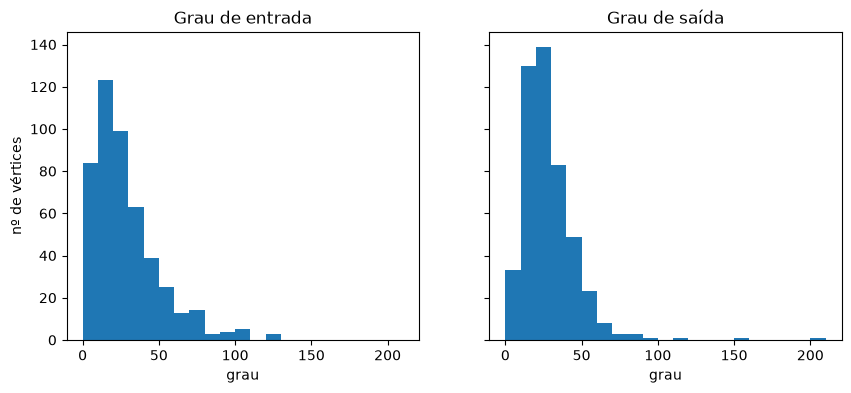

In [6]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
faixas = range(0, max(entrada + saida) + 10, 10)

ax1.hist(entrada, bins=faixas)
ax1.set_title("Grau de entrada")
ax1.set_xlabel("grau")
ax1.set_ylabel("nº de vértices")

ax2.hist(saida, bins=faixas)
ax2.set_title("Grau de saída")
ax2.set_xlabel("grau")

plt.show()

## Densidade

In [7]:
print(f"A densidade do grafo é {nx.density(G):.4f}")

A densidade do grafo é 0.0590


## Número de componentes conexas e tamanho de cada componente

In [8]:
fracas = list(nx.weakly_connected_components(G))
fortes = list(nx.strongly_connected_components(G))

tam_fracas = ", ".join(str(len(c)) for c in sorted(fracas, key=len, reverse=True))
tam_fortes = ", ".join(str(len(c)) for c in sorted(fortes, key=len, reverse=True))

print(f"Componentes fracamente conexas: {len(fracas)}, cujos tamanhos são: {tam_fracas}")
print(f"Componentes fortemente conexas: {len(fortes)}, cujos tamanhos são: {tam_fortes}")

Componentes fracamente conexas: 1, cujos tamanhos são: 475
Componentes fortemente conexas: 7, cujos tamanhos são: 469, 1, 1, 1, 1, 1, 1


## Diâmetro

In [9]:
diametro = nx.diameter(G) if nx.is_strongly_connected(G) else float("inf")

#O grafo não é fortemente conexo
# o diâmetro dirigido é infinito
# Assim, é calculado na maior componente forte e na componente fraca (não dirigida).

maior_forte = G.subgraph(max(fortes, key=len))
maior_fraca = G.subgraph(max(fracas, key=len)).to_undirected()

print(f"Diâmetro (dirigido, grafo inteiro): {diametro}")
diametro_forte = nx.diameter(maior_forte)
diametro_fraca = nx.diameter(maior_fraca)

print(f"Diâmetro (dirigido, maior componente forte): {diametro_forte}")
print(f"Diâmetro (componente fraca, não dirigido): {diametro_fraca}")

Diâmetro (dirigido, grafo inteiro): inf
Diâmetro (dirigido, maior componente forte): 6
Diâmetro (componente fraca, não dirigido): 4


## Raio

In [10]:
raio = nx.radius(G) if nx.is_strongly_connected(G) else float("inf")

raio_forte = nx.radius(maior_forte)
raio_fraca = nx.radius(maior_fraca)

print(f"Raio (dirigido, grafo inteiro): {raio}")
print(f"Raio (dirigido, maior componente forte): {raio_forte}")
print(f"Raio (componente fraca, não dirigido): {raio_fraca}")

Raio (dirigido, grafo inteiro): inf
Raio (dirigido, maior componente forte): 3
Raio (componente fraca, não dirigido): 2


## Comprimento médio dos caminhos

In [11]:
L = nx.average_shortest_path_length(G) if nx.is_strongly_connected(G) else float("inf")

L_forte = nx.average_shortest_path_length(maior_forte)
L_fraca = nx.average_shortest_path_length(maior_fraca)

print(f"Comprimento médio (dirigido, grafo inteiro): {L:.4f}")
print(f"Comprimento médio (dirigido, maior componente forte): {L_forte:.4f}")
print(f"Comprimento médio (componente fraca, não dirigido): {L_fraca:.4f}")

Comprimento médio (dirigido, grafo inteiro): inf
Comprimento médio (dirigido, maior componente forte): 2.3549
Comprimento médio (componente fraca, não dirigido): 2.0639


## Coeficiente de clusterização médio

In [12]:
clusterizacao = nx.average_clustering(maior_fraca)

print(f"Coeficiente de clusterização médio (não dirigido): {clusterizacao:.4f}")

Coeficiente de clusterização médio (não dirigido): 0.3014


## Número de triângulos

In [13]:
##É viável contar triângulos 
## cálculo feito com a componente conexa fraca (não dirigida)

triangulos = sum(nx.triangles(maior_fraca).values()) // 3

print(f"Número de triângulos (não dirigido): {triangulos}")

Número de triângulos (não dirigido): 52333


## Visualização do grafo

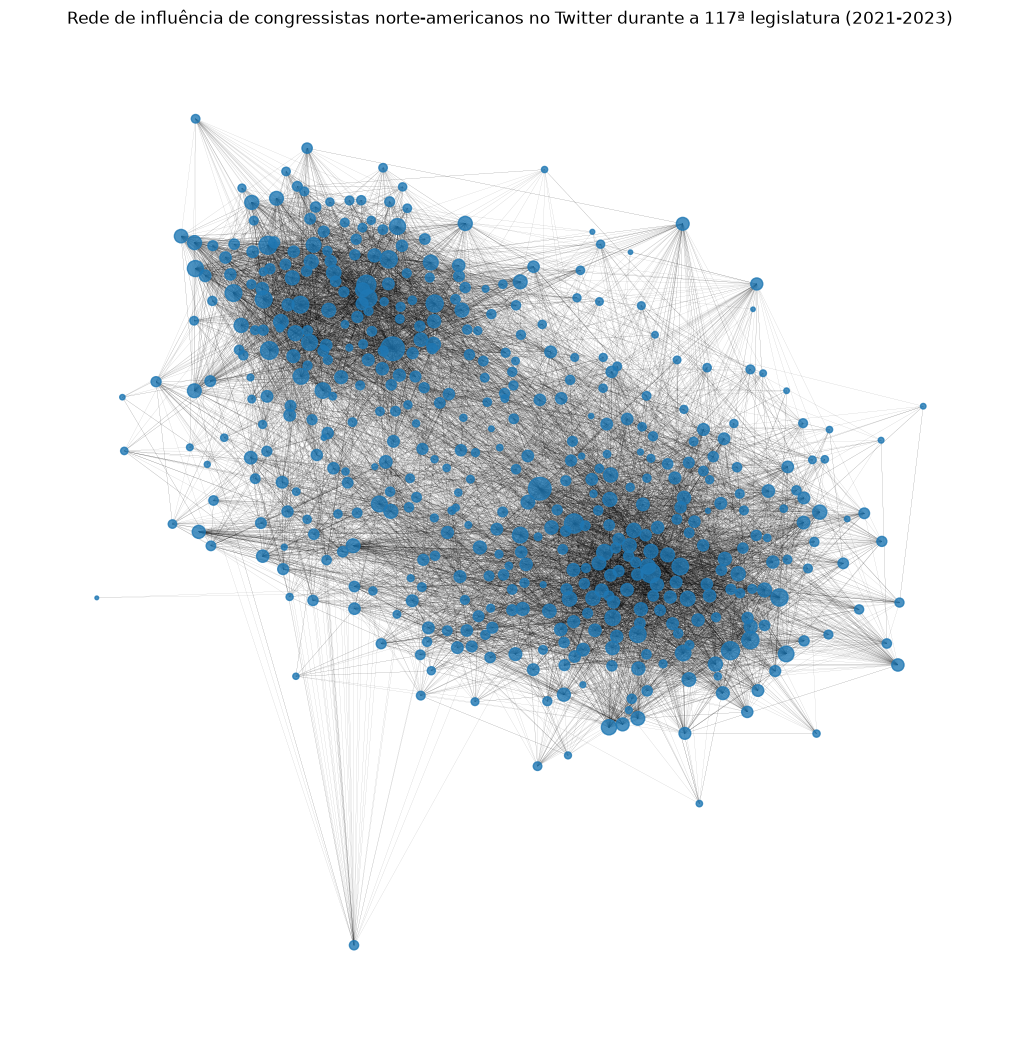

In [14]:
import matplotlib.pyplot as plt

pos = nx.spring_layout(G, seed=42)
tamanhos = [5 + G.degree(v) for v in G.nodes()]

plt.figure(figsize=(10, 10))
nx.draw(G, pos, node_size=tamanhos, width=0.05, arrows=False, alpha=0.8)
plt.title("Rede de influência de congressistas norte-americanos no Twitter durante a 117ª legislatura (2021-2023)")
plt.show()

## Exportar resultados

In [15]:
import csv
import os

os.makedirs("resultados", exist_ok=True)

def formatar(valor):
    if isinstance(valor, float) and valor != float("inf"):
        return f"{valor:.4f}"
    return valor

medidas = [
    ("vértices", "dirigido", G.number_of_nodes()),
    ("arestas", "dirigido", G.number_of_edges()),
    ("grau mínimo", "entrada", min(entrada)),
    ("grau máximo", "entrada", max(entrada)),
    ("grau médio", "entrada", sum(entrada) / len(entrada)),
    ("grau mínimo", "saída", min(saida)),
    ("grau máximo", "saída", max(saida)),
    ("grau médio", "saída", sum(saida) / len(saida)),
    ("densidade", "dirigido", nx.density(G)),
    ("componentes conexas", "fracas", len(fracas)),
    ("tamanhos das componentes", "fracas", tam_fracas),
    ("componentes conexas", "fortes", len(fortes)),
    ("tamanhos das componentes", "fortes", tam_fortes),
    ("diâmetro", "dirigido, grafo inteiro", diametro),
    ("diâmetro", "dirigido, maior componente forte", diametro_forte),
    ("diâmetro", "não dirigido, componente fraca", diametro_fraca),
    ("raio", "dirigido, grafo inteiro", raio),
    ("raio", "dirigido, maior componente forte", raio_forte),
    ("raio", "não dirigido, componente fraca", raio_fraca),
    ("comprimento médio dos caminhos", "dirigido, grafo inteiro", L),
    ("comprimento médio dos caminhos", "dirigido, maior componente forte", L_forte),
    ("comprimento médio dos caminhos", "não dirigido, componente fraca", L_fraca),
    ("coeficiente de clusterização médio", "não dirigido", clusterizacao),
    ("número de triângulos", "não dirigido", triangulos),
]

with open("resultados/estrutura_basica.csv", "w", newline="", encoding="utf-8") as f:
    escritor = csv.writer(f)
    escritor.writerow(["medida", "versao", "valor"])
    for medida, versao, valor in medidas:
        escritor.writerow([medida, versao, formatar(valor)])

print(f"{len(medidas)} medidas salvas em resultados/estrutura_basica.csv")

24 medidas salvas em resultados/estrutura_basica.csv
